# SeismicDataset. Часть 1: подготовка и исследование моделей #

## Глава 1.1. Предобработка и анализ EFVB/ECVB ##

### Задача

Установить устройство исходного набора, проверить физический смысл полей, описать без потери точности бинарное представление и получить общие шкалы визуализации и статистику материалов.

Это отчёт по завершённому этапу. Дневник читает сохранённый пересчёт 60000 моделей от 5 ноября 2026 года и строит обзорные графики. Он не запускает повторную конвертацию 120000 текстовых файлов и не генерирует массовые изображения. Команды полной предобработки вынесены в summary главы.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

from scripts.project_paths import DATA_11, IMG_11, PROJECT_ROOT
from scripts.reporting import dataset_summaries, mapping, read_json

## 1. Исходная постановка и формат данных ##

В `src/data_EFVB_out/` и `src/data_ECVB_out/` находятся по 30000 пар VP/VS. Одна модель — два массива 70×70: первая строка соответствует верху, столбцы направлены слева направо. Значения относятся к квадратным ячейкам 10×10 м; область имеет размеры 700×700 м. Плотность принята равной 1000 кг/м³.

EFVB содержит модели с прямыми слоями, ECVB — с криволинейными. Материал в статистике определяется точной float64-парой (VP, VS) при фиксированной плотности. Количество материалов не равно количеству связных областей.

In [2]:
statistics_path = DATA_11 / "dataset_statistics.json"
statistics = read_json(statistics_path)
groups = dataset_summaries(statistics_path)
manifest = read_json(DATA_11 / "binary/manifest.json")
assert sum(group.models for group in groups) == 60000
print("Источник статистики:", statistics_path.relative_to(PROJECT_ROOT))
print("Проверки исходных полей:", statistics["validation"])
print("Воспроизводимость:", statistics["digest_recipe"])

Источник статистики: data/dev_1_1_preprocessing/dataset_statistics.json
Проверки исходных полей: All 120000 text fields: paired IDs, shape, finite positive speeds, positive bulk modulus, bounds equal historical manifest
Воспроизводимость: SHA256 of ascending lines ID:SHA256(vp_raw + NUL + vs_raw) + LF


## 2. Глобальные диапазоны скоростей и материалов ##

In [3]:
rows = ["| Набор | Моделей | VP, м/с | VS, м/с | Материалов на модель |",
        "| --- | ---: | --- | --- | --- |"]
for group in groups:
    rows.append(f"| {group.name} | {group.models} | {group.vp[0]:.0f}–{group.vp[1]:.0f} | {group.vs[0]:.5f}–{group.vs[1]:.5f} | {group.materials[0]}–{group.materials[1]} |")
display(Markdown("\n".join(rows)))
historical_bounds = mapping(manifest["class_bounds"])
for group in groups:
    bounds = mapping(historical_bounds[group.name])
    assert group.vp == (bounds["vp_min"], bounds["vp_max"])
    assert group.vs == (bounds["vs_min"], bounds["vs_max"])
print("Сохранённая статистика совпадает с диапазонами исторического бинарного manifest.")

| Набор | Моделей | VP, м/с | VS, м/с | Материалов на модель |
| --- | ---: | --- | --- | --- |
| EFVB | 30000 | 1500–4500 | 615.71051–2995.11597 | 3–10 |
| ECVB | 30000 | 1500–4500 | 616.98389–2999.36597 | 3–12 |

Сохранённая статистика совпадает с диапазонами исторического бинарного manifest.


## 3. Распределение числа материалов ##

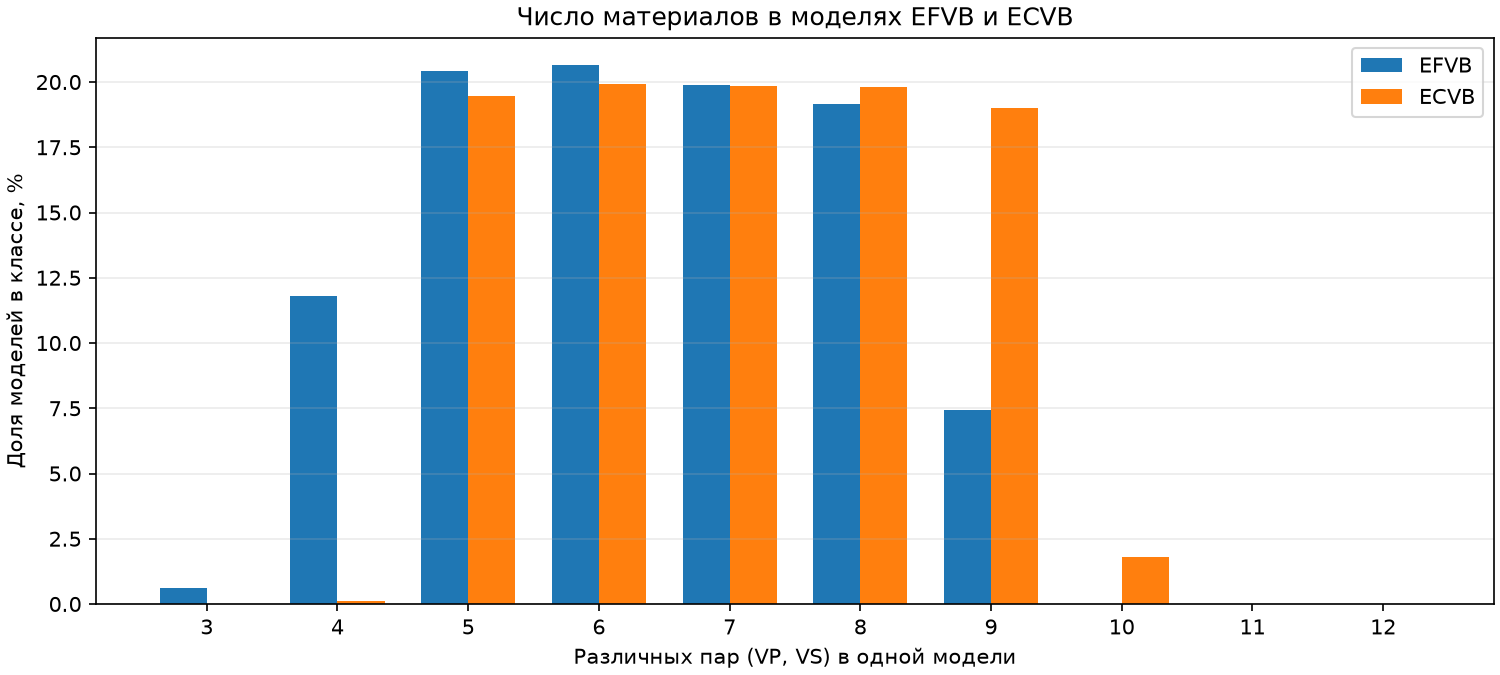

In [4]:
orders = np.arange(3, 13)
figure, axes = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for index, group in enumerate(groups):
    percentages = [100 * group.counts.get(int(order), 0) / group.models for order in orders]
    axes.bar(orders + (index - 0.5) * 0.36, percentages, width=0.36, label=group.name)
axes.set(title="Число материалов в моделях EFVB и ECVB", xlabel="Различных пар (VP, VS) в одной модели", ylabel="Доля моделей в классе, %", xticks=orders)
axes.legend()
axes.grid(axis="y", alpha=0.25)
IMG_11.mkdir(parents=True, exist_ok=True)
histogram_path = IMG_11 / "dev_1_1_material_count_histogram.png"
figure.savefig(histogram_path, dpi=150)
plt.close(figure)
display(Image(filename=str(histogram_path), width=950))

## 4. Единая цветовая шкала ##

Выбран вариант A: красный канал кодирует VP, зелёный — VS. Для каждой компоненты используются общие минимальное и максимальное значения по всем 60000 моделям, без локальной нормировки и отсечения. PNG служат только иллюстрациями; расчётным источником являются числовые поля.

### EFVB: обзор 16 равномерно выбранных ID

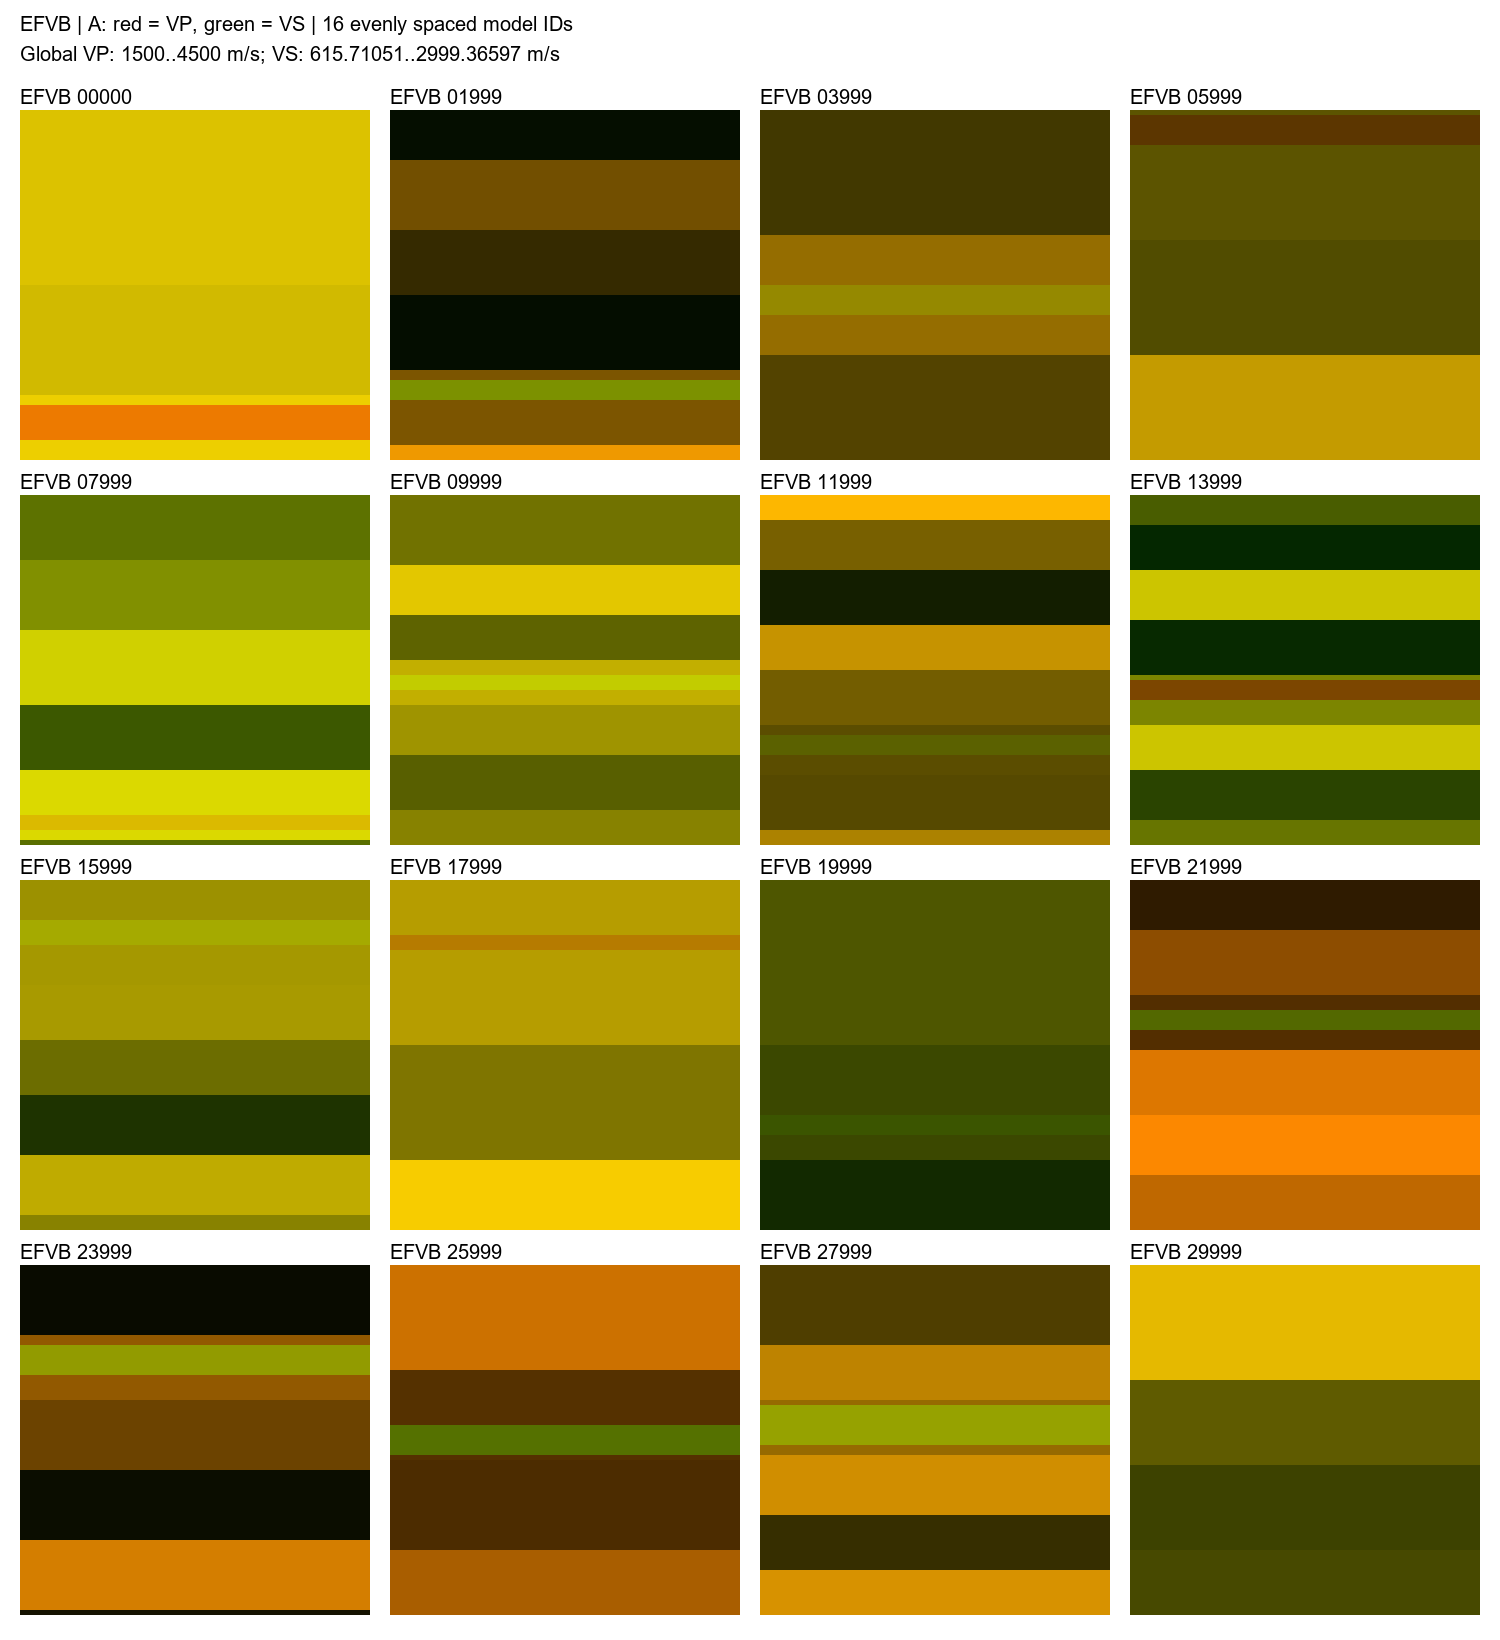

### ECVB: обзор 16 равномерно выбранных ID

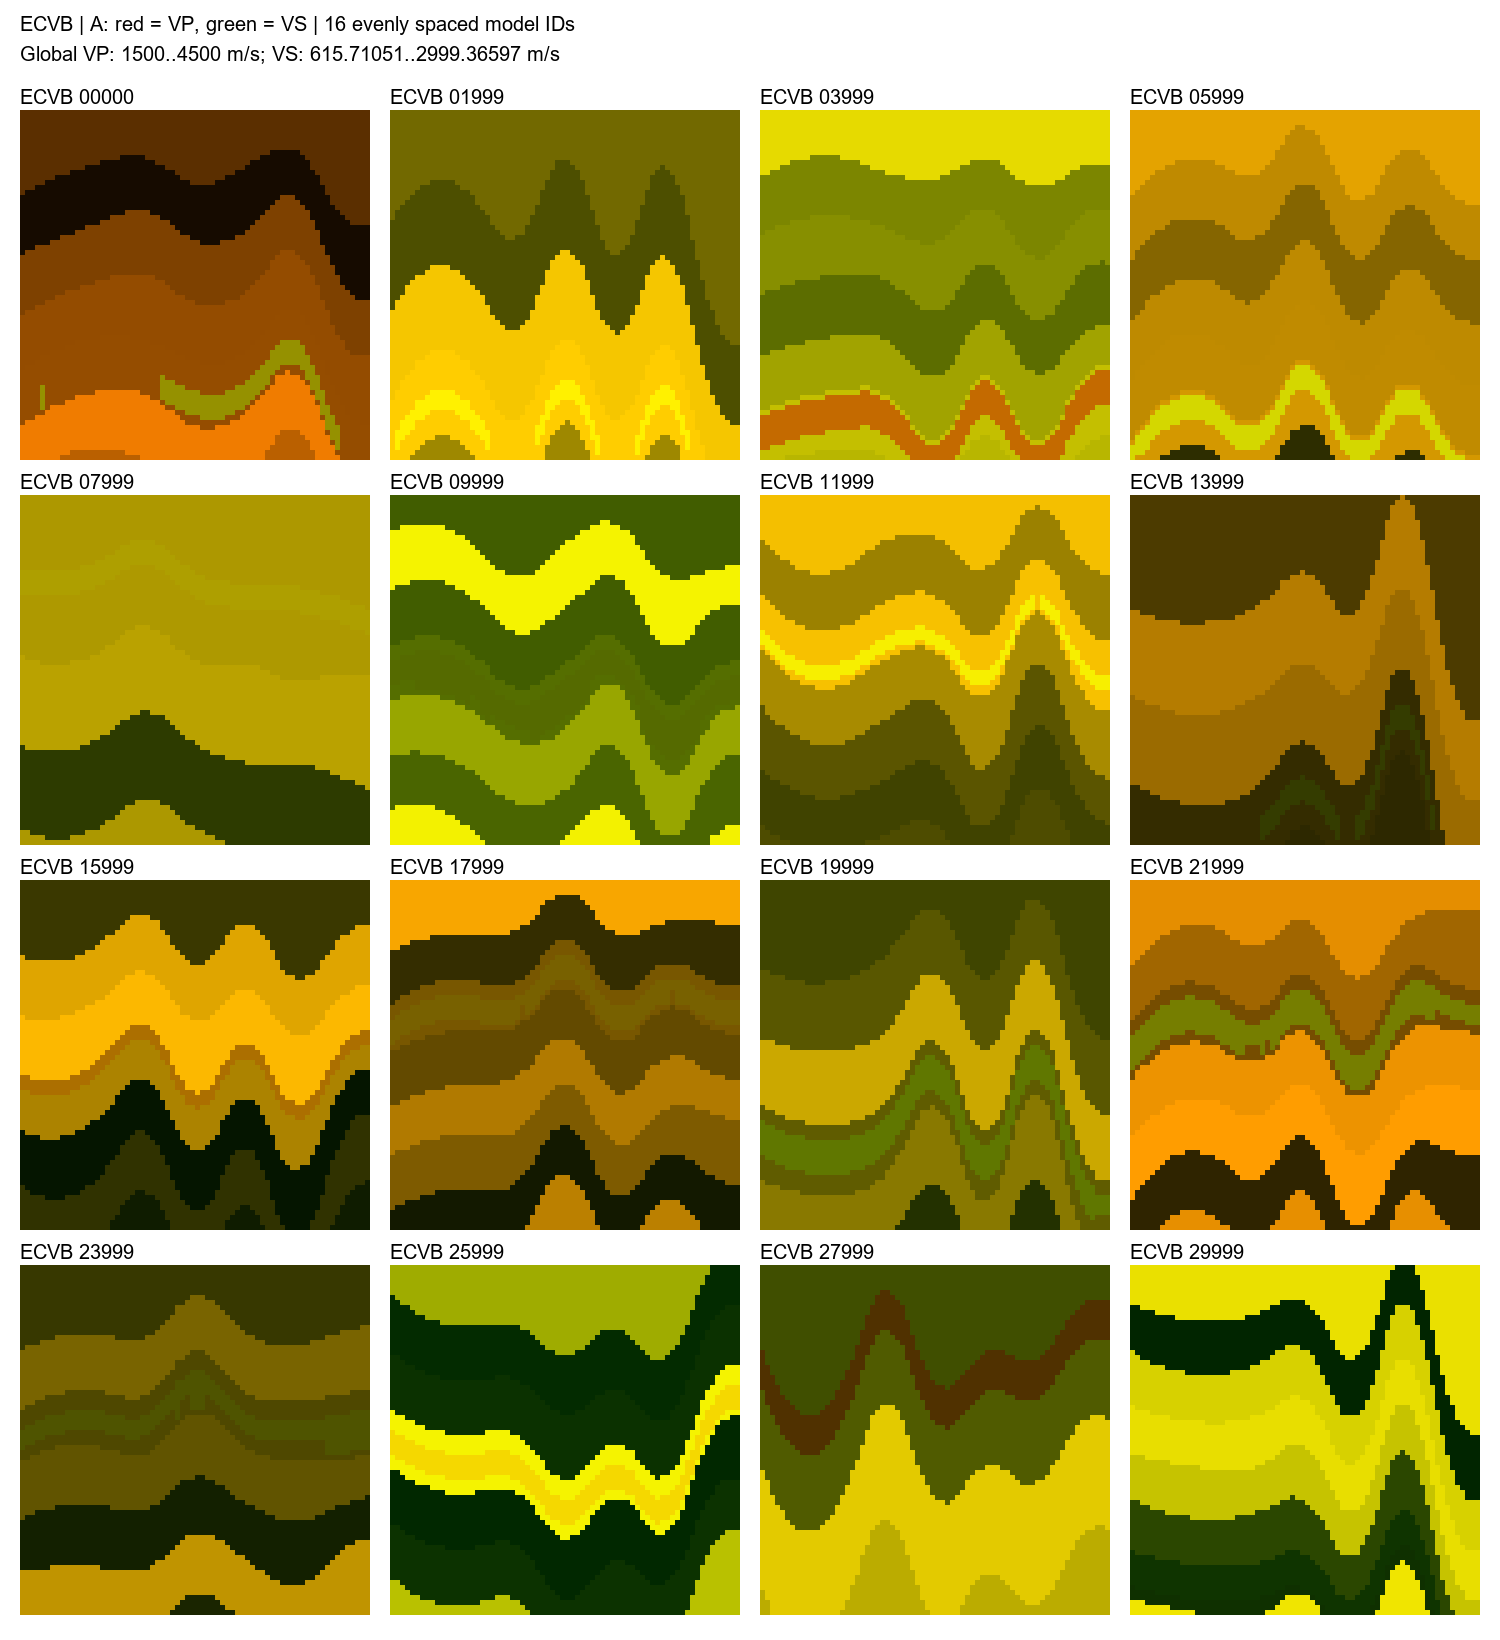

In [5]:
for name in ("EFVB", "ECVB"):
    display(Markdown(f"### {name}: обзор 16 равномерно выбранных ID"))
    display(Image(filename=str(IMG_11 / "previews" / "A" / f"{name}_overview.png"), width=850))

## 5. Бинарный формат и доступность данных ##

Историческая конвертация сохраняет `ids`, `vp`, `vs` в сжатых NPZ по 1000 моделей; скорости имеют dtype float64. Каждый блок был повторно открыт и точно сопоставлен с разобранным текстом. Manifest описывает 60 блоков, контрольные суммы, оси, единицы и физические проверки.

На этой машине перенесены компактный manifest и исходные распакованные тексты. Основные бинарные блоки отсутствовали в исходной рабочей папке и не создавались при оформлении проекта. Наличие manifest описывает завершённую историческую конвертацию, но не означает локального наличия всех NPZ. Конвертер поддерживает исходные ZIP и уже распакованные каталоги; для новой серии необходимо задать новый выходной каталог.

In [6]:
print("Исходные каталоги:")
for group in groups:
    source_path = PROJECT_ROOT / "src" / f"data_{group.name}_out"
    print(f"  {source_path.relative_to(PROJECT_ROOT)}: {'доступен' if source_path.is_dir() else 'восстановить из хранилища'}")
print("Локальных основных NPZ-блоков:", len(list((DATA_11 / "binary").glob("*.npz"))))

Исходные каталоги:
  src/data_EFVB_out: доступен
  src/data_ECVB_out: доступен
Локальных основных NPZ-блоков: 0


## Выводы ##

Этап 1.1 завершён в объёме предобработки и анализа: определены оси и единицы, проверены 60000 моделей, установлены диапазоны VP/VS и точного числа материалов, сохранены общая цветовая шкала и описание бинарного формата. EFVB содержит 3–10, ECVB — 3–12 материалов на модель.

Отчётный запуск проверяет согласованность сохранённых компактных результатов и строит график распределения материалов. Он не является новой проверкой всех исходных полей и не подтверждает пригодность каждой модели для выбранного численного решателя. Следующий этап — пробная оценка влияния сглаживания границ на волновой ответ.